# C1 – Model training: Personalized, Routine-Aware EV Charging Scheduling

**Project J26-IT-430 · Component 1 (When should each EV charge?)**

This notebook trains and evaluates the C1 models on the **cleaned data** in `charging_scheduling/data/processed/`
(made by `python -m charging_scheduling.data_prep.run_all`). Raw data is never touched.

| Section | Model | Compared with (baseline) |
| --- | --- | --- |
| 1.1a | Sri Lankan household **base-load forecast** (day-ahead, 15-min, XGBoost) | same time last week (seasonal-naive), same time yesterday |
| 1.1b | **EV charging demand** forecast (ACN, day-ahead, 15-min, XGBoost) | same two baselines |
| 1.2 | **Routine clustering** of drivers (K-Means, elbow + silhouette) | – |
| 1.3 | **Need prediction**: departure time + kWh (XGBoost, quantile q10 for safe departure) | profile defaults, driver's own app input |
| 1.4 | **Coordinated scheduler** (LP, minimise peak) – *scenario* | B1 uncontrolled, B2 fixed TOU 22:30, B3 TOU + random delay, B4 coordinated without personal info |

Rules followed (CLAUDE.md): real data for training/testing · **time-based splits** · every method vs a baseline ·
`SEED = 42` · results + config saved to `results/`. Section 1.4 uses a **scenario** (simulated home-charging
sessions) – it shows how the scheduler behaves, it is **not** a model-accuracy test.

## 0. Setup

In [1]:
import json, sys, time, warnings
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from scipy.optimize import linprog
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.preprocessing import StandardScaler
import xgboost as xgb

warnings.filterwarnings("ignore", category=FutureWarning)

# find the project root (folder that contains CLAUDE.md) and make shared/ + charging_scheduling/ importable
ROOT = Path.cwd()
while not (ROOT / "CLAUDE.md").exists() and ROOT.parent != ROOT:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from shared import config
from charging_scheduling.data_prep.run_all import BASELOAD_SPLIT, SESSION_SPLITS

SEED = config.SEED
rng = np.random.default_rng(SEED)
C1 = ROOT / "charging_scheduling"
PROC = C1 / "data" / "processed"
RES = C1 / "results"; FIG = RES / "figures"
FIG.mkdir(parents=True, exist_ok=True)
RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
RESULTS = {"run_id": RUN_ID, "seed": SEED, "config": {}, "metrics": {}}
plt.rcParams.update({"figure.figsize": (11, 3.6), "axes.grid": True, "grid.alpha": 0.3})
print("project root:", ROOT, "| run:", RUN_ID, "| xgboost", xgb.__version__)

project root: C:\Users\dasit\Documents\Projects\CSP 002\A Shared Intelligent Infrastructure Framework for Electric Vehicles in Sri Lanka | run: 20261019T090804Z | xgboost 3.4.1


In [2]:
def mae(y, p):  return float(np.mean(np.abs(np.asarray(y) - np.asarray(p))))
def rmse(y, p): return float(np.sqrt(np.mean((np.asarray(y) - np.asarray(p)) ** 2)))
def wape(y, p): return float(np.sum(np.abs(np.asarray(y) - np.asarray(p))) / np.sum(np.abs(y)) * 100)  # % (safe when y has zeros)
def mape(y, p): return float(np.mean(np.abs((np.asarray(y) - np.asarray(p)) / np.asarray(y))) * 100)

def split_by_dates(index, c):
    s = pd.Series("excluded", index=index)
    t = index
    s[(t >= pd.Timestamp(c["start"], tz="UTC")) & (t < pd.Timestamp(c["val"], tz="UTC"))] = "train"
    s[(t >= pd.Timestamp(c["val"], tz="UTC")) & (t < pd.Timestamp(c["test"], tz="UTC"))] = "val"
    s[(t >= pd.Timestamp(c["test"], tz="UTC")) & (t < pd.Timestamp(c["end"], tz="UTC"))] = "test"
    return s

## Data overview

In [3]:
base = pd.read_parquet(PROC / "recon_baseload_15min.parquet")
sess = pd.read_parquet(PROC / "ev_sessions_clean.parquet")
users = pd.read_parquet(PROC / "ev_users_summary.parquet")
print(f"base load slots: {len(base):,}  ({base.interval_start_utc.min():%Y-%m-%d} -> {base.interval_start_utc.max():%Y-%m-%d})")
print(f"EV sessions: {len(sess):,}"); display(sess.groupby(["source", "split"]).size().unstack(fill_value=0))
print(f"drivers with ID: {len(users):,} | with >= 10 sessions: {int(users.has_10_plus_sessions.sum()):,}")

base load slots: 35,712  (2023-09-30 -> 2024-12-23)
EV sessions: 189,606


split,excluded,test,train,val
source,,,,
acn,12922,9141,36949,7617
boulder,0,8604,51839,7156
utrecht,0,8347,38977,8054


drivers with ID: 4,416 | with >= 10 sessions: 1,488


## 1.1 Forecasting (day-ahead, 15-minute)

**Idea:** at midnight we must know tomorrow's load, so every input feature is at least **24 h old**
(lag ≥ 96 slots). Features: same slot 1/2/3 days ago, 1/2 weeks ago, average of the last full day,
average of the same slot over the last 4 weeks, slot of day, weekday, weekend, month.
Missing days in the data stay missing (XGBoost handles NaN inputs; rows with no target are not scored).

**Baselines:** *seasonal-naive* = same time last week (CLAUDE.md), and *yesterday* = same time 24 h ago.
All methods are scored on exactly the same test rows.

In [4]:
LAGS = (96, 192, 288, 672, 1344)

def make_features(s: pd.Series, tz: str) -> pd.DataFrame:
    df = pd.DataFrame({"y": s})
    local = df.index.tz_convert(tz)
    df["slot"] = local.hour * 4 + local.minute // 15
    df["weekday"] = local.dayofweek
    df["is_weekend"] = (local.dayofweek >= 5).astype(int)
    df["month"] = local.month
    for L in LAGS:
        df[f"lag_{L}"] = s.shift(L)
    df["mean_prev_day"] = s.shift(96).rolling(96, min_periods=80).mean()
    df["mean_same_slot_4w"] = pd.concat([s.shift(672 * k) for k in (1, 2, 3, 4)], axis=1).mean(axis=1)
    return df

FEATS = ["slot", "weekday", "is_weekend", "month", *[f"lag_{L}" for L in LAGS], "mean_prev_day", "mean_same_slot_4w"]

def train_forecaster(s: pd.Series, split: pd.Series, tz: str, name: str):
    df = make_features(s, tz).assign(split=split)
    tr = df[(df.split == "train") & df.y.notna()]
    va = df[(df.split == "val") & df.y.notna()]
    te = df[(df.split == "test") & df.y.notna() & df.lag_672.notna() & df.lag_96.notna()]
    model = xgb.XGBRegressor(n_estimators=3000, learning_rate=0.03, max_depth=6, subsample=0.8,
                             colsample_bytree=0.8, min_child_weight=5, random_state=SEED,
                             early_stopping_rounds=100, eval_metric="mae")
    t0 = time.time()
    model.fit(tr[FEATS], tr.y, eval_set=[(va[FEATS], va.y)], verbose=False)
    pred = pd.Series(model.predict(te[FEATS]), index=te.index)
    m = {}
    for label, p in (("seasonal_naive_last_week", te.lag_672), ("naive_yesterday", te.lag_96), ("xgboost", pred)):
        m[label] = {"MAE": mae(te.y, p), "RMSE": rmse(te.y, p), "WAPE_%": wape(te.y, p)}
        if (te.y > 0).all():
            m[label]["MAPE_%"] = mape(te.y, p)
    best = m["seasonal_naive_last_week"]["MAE"]
    m["xgboost"]["MAE_improvement_vs_seasonal_naive_%"] = 100 * (1 - m["xgboost"]["MAE"] / best)
    info = {"rows_train": len(tr), "rows_val": len(va), "rows_test_scored": len(te),
            "best_iteration": int(model.best_iteration), "fit_seconds": round(time.time() - t0, 1)}
    model.save_model(RES / f"{name}_xgb_{RUN_ID}.json")
    return model, te.assign(pred=pred), m, info

### 1.1a Sri Lankan household base load (RECON-SL)
Target = average kW per household in each 15-min slot (Colombo local time).

In [5]:
s_base = base.set_index("interval_start_utc")["mean_kw"].asfreq("15min")
split_base = split_by_dates(s_base.index, BASELOAD_SPLIT)
print("slots in range:", len(s_base), "| missing (no data):", int(s_base.isna().sum()))
m_base, te_base, met_base, info_base = train_forecaster(s_base, split_base, "Asia/Colombo", "baseload")
RESULTS["metrics"]["1.1a_baseload_forecast"] = met_base | {"info": info_base}
display(pd.DataFrame(met_base).T.round(4)); print(info_base)

slots in range: 43152 | missing (no data): 7440


,MAE,RMSE,WAPE_%,MAPE_%,MAE_improvement_vs_seasonal_naive_%
seasonal_naive_last_week,0.0219,0.0290,9.7589,9.6885,NaN
naive_yesterday,0.0129,0.0175,5.7387,5.8004,NaN
xgboost,0.0132,0.0180,5.9000,6.0669,39.5423


{'rows_train': 22343, 'rows_val': 6815, 'rows_test_scored': 6554, 'best_iteration': 133, 'fit_seconds': 1.4}


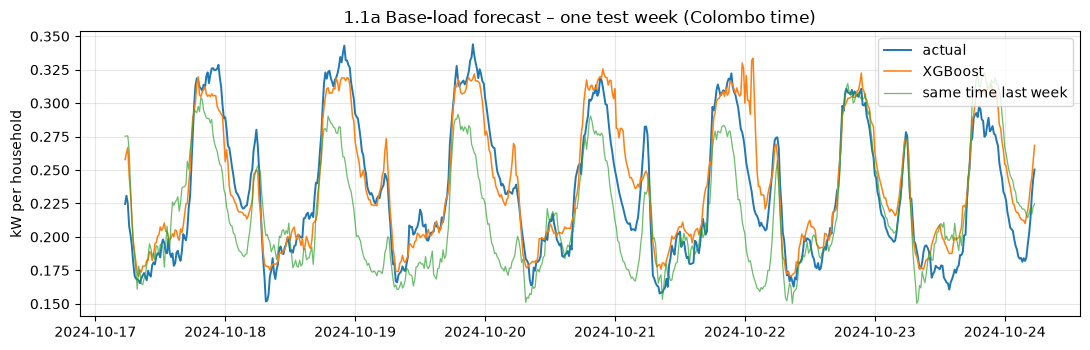

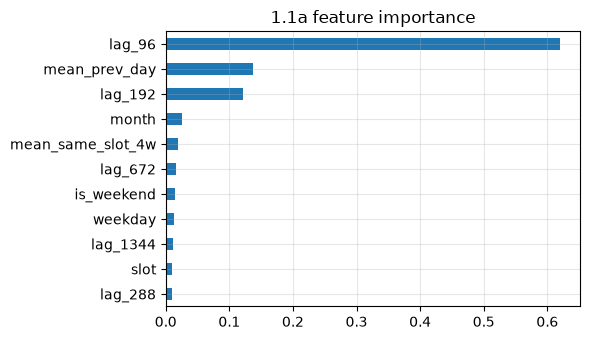

In [6]:
week = te_base.index[0].normalize() + pd.Timedelta(days=1)
w = te_base.loc[week: week + pd.Timedelta(days=7)]
fig, ax = plt.subplots()
ax.plot(w.index.tz_convert("Asia/Colombo"), w.y, label="actual", lw=1.4)
ax.plot(w.index.tz_convert("Asia/Colombo"), w.pred, label="XGBoost", lw=1.1)
ax.plot(w.index.tz_convert("Asia/Colombo"), w.lag_672, label="same time last week", lw=0.9, alpha=0.7)
ax.set_ylabel("kW per household"); ax.set_title("1.1a Base-load forecast – one test week (Colombo time)"); ax.legend()
fig.tight_layout(); fig.savefig(FIG / "1_1a_baseload_test_week.png", dpi=120); plt.show()
imp = pd.Series(m_base.feature_importances_, index=FEATS).sort_values()
imp.plot.barh(figsize=(6, 3.5), title="1.1a feature importance"); plt.tight_layout(); plt.show()

### 1.1b EV charging demand (ACN, pre-COVID)
Each session's energy is spread evenly from plug-in until charging finished (or unplug), giving total EV kW
per 15-min slot for the ACN sites (local time America/Los_Angeles). Same features and baselines as 1.1a.

In [7]:
def sessions_to_load(df: pd.DataFrame, start, end) -> pd.Series:
    idx = pd.date_range(start, end, freq="15min", tz="UTC", inclusive="left")
    t0 = idx[0]
    finish = df["done_charging_utc"].fillna(df["departure_utc"]).clip(upper=df["departure_utc"])
    a = ((df["arrival_utc"] - t0) / pd.Timedelta("15min")).astype(int).to_numpy()
    b = np.maximum(((finish - t0) / pd.Timedelta("15min")).astype(int).to_numpy(), a + 1)
    kw = df["kwh"].to_numpy() / ((b - a) * 0.25)
    diff = np.zeros(len(idx) + 1)
    ok = (a >= 0) & (b <= len(idx))
    np.add.at(diff, a[ok], kw[ok]); np.add.at(diff, b[ok], -kw[ok])
    return pd.Series(np.cumsum(diff)[:-1], index=idx)

acn = sess[(sess.source == "acn") & (sess.split != "excluded")]
c = SESSION_SPLITS["acn"]
s_ev = sessions_to_load(acn, c["start"], c["end"])
s_ev = s_ev[s_ev.index >= acn.arrival_utc.min().floor("D")]
split_ev = split_by_dates(s_ev.index, c)
m_ev, te_ev, met_ev, info_ev = train_forecaster(s_ev, split_ev, "America/Los_Angeles", "ev_demand_acn")
RESULTS["metrics"]["1.1b_ev_demand_forecast"] = met_ev | {"info": info_ev}
display(pd.DataFrame(met_ev).T.round(3)); print(info_ev)

,MAE,RMSE,WAPE_%,MAE_improvement_vs_seasonal_naive_%
seasonal_naive_last_week,18.402,35.417,45.720,NaN
naive_yesterday,24.896,47.109,61.852,NaN
xgboost,12.602,22.536,31.310,31.52


{'rows_train': 44448, 'rows_val': 8832, 'rows_test_scored': 11616, 'best_iteration': 145, 'fit_seconds': 1.5}


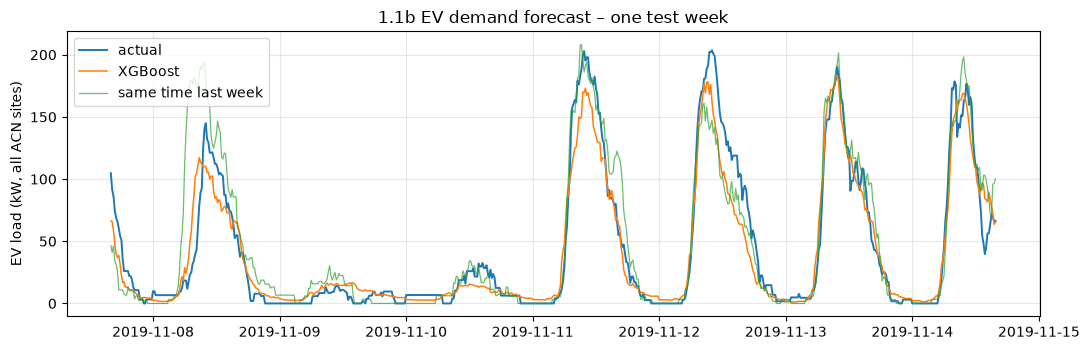

In [8]:
w = te_ev.iloc[96 * 7: 96 * 14]
fig, ax = plt.subplots()
ax.plot(w.index.tz_convert("America/Los_Angeles"), w.y, label="actual", lw=1.4)
ax.plot(w.index.tz_convert("America/Los_Angeles"), w.pred, label="XGBoost", lw=1.1)
ax.plot(w.index.tz_convert("America/Los_Angeles"), w.lag_672, label="same time last week", lw=0.9, alpha=0.7)
ax.set_ylabel("EV load (kW, all ACN sites)"); ax.set_title("1.1b EV demand forecast – one test week"); ax.legend()
fig.tight_layout(); fig.savefig(FIG / "1_1b_ev_demand_test_week.png", dpi=120); plt.show()

## 1.2 Routine clustering (K-Means)

One row per driver (ACN + Utrecht, shared Utrecht IDs removed), built **only from the driver's training
sessions** (no peeking at the test period). Drivers need **≥ 10 training sessions** (cold-start rule).
Features: average plug-in hour, how much it varies, average stay, average kWh, weekend share, sessions per week.
k is chosen with the elbow curve and the silhouette score (higher = clearer groups).

*Note:* ACN and Utrecht are **workplace** chargers, so the routine types found here are workplace patterns.
Home-charging routines (office commuter at home, shift worker, taxi) need the Sri Lankan pilot data.

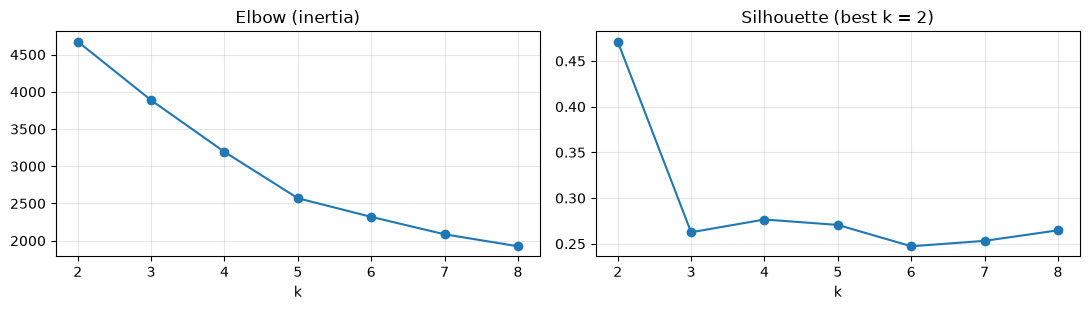

drivers clustered: 1016  (ACN 344, Utrecht 672)


In [9]:
tr_sess = sess[(sess.split == "train") & sess.user_id.notna() & ~sess.flag_shared_id]
g = tr_sess.groupby("user_id")
weeks = ((g.arrival_utc.max() - g.arrival_utc.min()).dt.days / 7).clip(lower=1)
U = pd.DataFrame({
    "n": g.size(), "source": g.source.first(),
    "arr_mean_h": g.arrival_hour_local.mean(), "arr_std_h": g.arrival_hour_local.std(),
    "stay_mean_h": g.stay_h.mean(), "kwh_mean": g.kwh.mean(),
    "weekend_share": g.is_weekend.mean(), "sessions_per_week": g.size() / weeks,
})
U = U[U.n >= 10].dropna()
CF = ["arr_mean_h", "arr_std_h", "stay_mean_h", "kwh_mean", "weekend_share", "sessions_per_week"]
X = StandardScaler().fit_transform(U[CF])
ks, inertia, sil, dbi = range(2, 9), [], [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(X)
    inertia.append(km.inertia_); sil.append(silhouette_score(X, km.labels_)); dbi.append(davies_bouldin_score(X, km.labels_))
K = list(ks)[int(np.argmax(sil))]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
ax[0].plot(list(ks), inertia, "o-"); ax[0].set_title("Elbow (inertia)"); ax[0].set_xlabel("k")
ax[1].plot(list(ks), sil, "o-"); ax[1].set_title(f"Silhouette (best k = {K})"); ax[1].set_xlabel("k")
fig.tight_layout(); fig.savefig(FIG / "1_2_choose_k.png", dpi=120); plt.show()
print(f"drivers clustered: {len(U)}  (ACN {int((U.source=='acn').sum())}, Utrecht {int((U.source=='utrecht').sum())})")

In [10]:
km = KMeans(n_clusters=K, n_init=20, random_state=SEED).fit(X)
U["routine_type"] = km.labels_
prof = U.groupby("routine_type")[CF].mean().round(2).assign(drivers=U.groupby("routine_type").size())

def describe(r):
    when = "early" if r.arr_mean_h < 8.5 else ("late-morning" if r.arr_mean_h < 11 else "afternoon/evening")
    stay = "long stay" if r.stay_mean_h >= 7 else ("medium stay" if r.stay_mean_h >= 3.5 else "short stay")
    reg = "very regular" if r.arr_std_h < 1 else "irregular"
    wk = ", weekend user" if r.weekend_share > 0.2 else ""
    return f"{when} arrival, {stay}, {reg}{wk}"

prof["description"] = prof.apply(describe, axis=1)
display(prof)
U.reset_index().to_parquet(RES / f"routine_clusters_{RUN_ID}.parquet", index=False)
RESULTS["metrics"]["1.2_routine_clustering"] = {
    "drivers": len(U), "k": K, "silhouette": float(max(sil)), "davies_bouldin": float(dbi[K - 2]),
    "cluster_sizes": prof["drivers"].to_dict(), "descriptions": prof["description"].to_dict()}

,arr_mean_h,arr_std_h,stay_mean_h,kwh_mean,weekend_share,sessions_per_week,drivers,description
routine_type,,,,,,,,
0,13.85,3.38,5.13,12.42,0.19,1.46,130,"afternoon/evening arrival, medium stay, irregular"
1,9.11,1.46,6.82,20.29,0.00,1.29,886,"late-morning arrival, medium stay, irregular"


## 1.3 Need prediction – departure time and energy (ACN)

For every session we predict **how long the car stays (→ departure time)** and **how many kWh it needs**,
using only information available at plug-in:
* the arrival time (hour, weekday, site),
* the driver's **own past sessions only** (count, average stay, average kWh, last stay …) – computed in time order,
* (optional variant) the driver's app input (requested kWh, minutes available).

A **quantile model (q10)** gives a *safe early* departure: the car should still be there at that time
in ~90 % of cases – the scheduler uses it so the car is ready.

**Baselines:** *profile default* = typical stay/kWh for that site and arrival hour (training data),
*driver input* = what the driver typed in the app. **Cold start:** drivers with < 10 past sessions get the default.

In [11]:
A = sess[(sess.source == "acn") & sess.user_id.notna()].sort_values("arrival_utc").copy()
A["dep_hour"] = A["arrival_hour_local"] + A["stay_h"]
gu = A.groupby("user_id")
A["prev_n"] = gu.cumcount()
for col, name in (("stay_h", "stay"), ("kwh", "kwh"), ("arrival_hour_local", "arr")):
    A[f"prev_mean_{name}"] = gu[col].transform(lambda x: x.shift().expanding().mean())
A["prev_std_stay"] = gu["stay_h"].transform(lambda x: x.shift().expanding().std())
A["prev_last_stay"] = gu["stay_h"].shift()
A["prev_last_kwh"] = gu["kwh"].shift()
A["arr_minus_usual"] = A["arrival_hour_local"] - A["prev_mean_arr"]
A["site_code"] = A["site"].map({"caltech": 0, "jpl": 1, "office001": 2})
A["arr_hour_bin"] = A["arrival_hour_local"].astype(int)

BASE_F = ["arrival_hour_local", "weekday", "is_weekend", "site_code", "prev_n", "prev_mean_stay", "prev_mean_kwh",
          "prev_mean_arr", "prev_std_stay", "prev_last_stay", "prev_last_kwh", "arr_minus_usual"]
INPUT_F = BASE_F + ["kwh_requested", "minutes_available"]

tr, va, te = (A[A.split == s] for s in ("train", "val", "test"))
default = tr.groupby(["site", "arr_hour_bin"])[["stay_h", "kwh"]].median()
glob = tr[["stay_h", "kwh"]].median()

def profile_default(df):
    d = df[["site", "arr_hour_bin"]].merge(default, left_on=["site", "arr_hour_bin"], right_index=True, how="left")
    return d["stay_h"].fillna(glob.stay_h).to_numpy(), d["kwh"].fillna(glob.kwh).to_numpy()

def fit_xgb(feats, target, objective="reg:squarederror", alpha=None):
    params = dict(n_estimators=2000, learning_rate=0.03, max_depth=5, subsample=0.8, colsample_bytree=0.8,
                  min_child_weight=5, random_state=SEED, early_stopping_rounds=100, objective=objective)
    if alpha is not None:
        params["quantile_alpha"] = alpha
    m = xgb.XGBRegressor(**params)
    m.fit(tr[feats], tr[target], eval_set=[(va[feats], va[target])], verbose=False)
    return m

models = {
    "stay_personal": fit_xgb(BASE_F, "stay_h"), "kwh_personal": fit_xgb(BASE_F, "kwh"),
    "stay_q10": fit_xgb(BASE_F, "stay_h", "reg:quantileerror", 0.10),
    "stay_with_input": fit_xgb(INPUT_F, "stay_h"), "kwh_with_input": fit_xgb(INPUT_F, "kwh"),
}
for k, m in models.items():
    m.save_model(RES / f"need_{k}_{RUN_ID}.json")
print({k: int(m.best_iteration) for k, m in models.items()})

{'stay_personal': 166, 'kwh_personal': 218, 'stay_q10': 807, 'stay_with_input': 165, 'kwh_with_input': 638}


In [12]:
def evaluate(df, label):
    d_stay, d_kwh = profile_default(df)
    warm = (df.prev_n >= 10).to_numpy()
    p_stay = np.where(warm, models["stay_personal"].predict(df[BASE_F]), d_stay)   # cold start -> default
    p_kwh = np.where(warm, models["kwh_personal"].predict(df[BASE_F]), d_kwh)
    q10 = np.where(warm, models["stay_q10"].predict(df[BASE_F]), np.nan)
    r = {"sessions": len(df), "warm_share_%": 100 * warm.mean(),
         "departure_MAE_min": {"profile_default": 60 * mae(df.stay_h, d_stay), "personal_model": 60 * mae(df.stay_h, p_stay)},
         "energy_MAE_kWh": {"profile_default": mae(df.kwh, d_kwh), "personal_model": mae(df.kwh, p_kwh)},
         "warm_only": {"departure_MAE_min_default": 60 * mae(df.stay_h[warm], d_stay[warm]),
                       "departure_MAE_min_personal": 60 * mae(df.stay_h[warm], p_stay[warm]),
                       "energy_MAE_kWh_default": mae(df.kwh[warm], d_kwh[warm]),
                       "energy_MAE_kWh_personal": mae(df.kwh[warm], p_kwh[warm]),
                       "q10_coverage_% (target ~90)": 100 * float(np.mean(df.stay_h[warm] >= q10[warm]))}}
    has = df.minutes_available.notna() & df.kwh_requested.notna()
    if has.any():
        h = df[has]
        r["with_app_input"] = {
            "sessions": int(has.sum()),
            "departure_MAE_min_driver_input": 60 * mae(h.stay_h, h.minutes_available / 60),
            "departure_MAE_min_model_with_input": 60 * mae(h.stay_h, models["stay_with_input"].predict(h[INPUT_F])),
            "energy_MAE_kWh_driver_input": mae(h.kwh, h.kwh_requested),
            "energy_MAE_kWh_model_with_input": mae(h.kwh, models["kwh_with_input"].predict(h[INPUT_F]))}
    return r

need_res = evaluate(te, "test")
RESULTS["metrics"]["1.3_need_prediction_test"] = need_res
print(json.dumps(need_res, indent=1, default=lambda x: round(float(x), 2)))

{
 "sessions": 7982,
 "warm_share_%": 90.8168378852418,
 "departure_MAE_min": {
  "profile_default": 104.89465881566859,
  "personal_model": 90.41045159998468
 },
 "energy_MAE_kWh": {
  "profile_default": 7.307842430946781,
  "personal_model": 4.229473577573136
 },
 "warm_only": {
  "departure_MAE_min_default": 101.5436968317469,
  "departure_MAE_min_personal": 85.59488430648977,
  "energy_MAE_kWh_default": 7.282857472055224,
  "energy_MAE_kWh_personal": 3.8932119778314083,
  "q10_coverage_% (target ~90)": 87.18443923299766
 },
 "with_app_input": {
  "sessions": 7982,
  "departure_MAE_min_driver_input": 157.7945084774075,
  "departure_MAE_min_model_with_input": 86.36340206718222,
  "energy_MAE_kWh_driver_input": 11.75513930516377,
  "energy_MAE_kWh_model_with_input": 3.7741136968814457
 }
}


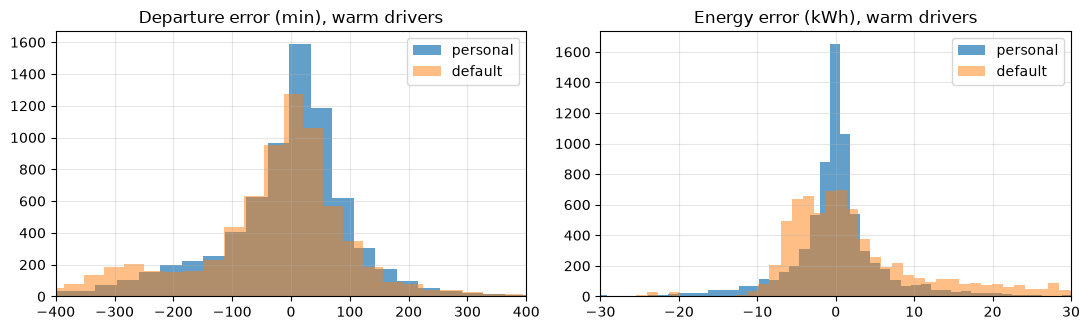

In [13]:
warm = te[te.prev_n >= 10]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].hist((warm.stay_h - models["stay_personal"].predict(warm[BASE_F])) * 60, bins=60, alpha=0.7, label="personal")
ax[0].hist((warm.stay_h - profile_default(warm)[0]) * 60, bins=60, alpha=0.5, label="default")
ax[0].set_xlim(-400, 400); ax[0].set_title("Departure error (min), warm drivers"); ax[0].legend()
ax[1].hist(warm.kwh - models["kwh_personal"].predict(warm[BASE_F]), bins=60, alpha=0.7, label="personal")
ax[1].hist(warm.kwh - profile_default(warm)[1], bins=60, alpha=0.5, label="default")
ax[1].set_xlim(-30, 30); ax[1].set_title("Energy error (kWh), warm drivers"); ax[1].legend()
fig.tight_layout(); fig.savefig(FIG / "1_3_need_errors.png", dpi=120); plt.show()

## 1.4 Coordinated scheduler – scenario (LP)

**Scenario (not an accuracy test):** a Colombo feeder with `N_HOMES` homes; `N_EV` of them have an EV and
charge at home overnight. Base load = real RECON-SL household load for one **test-period weekday**
× number of homes. EV sessions are **simulated** (arrival ~18:30 ± 1.2 h, departure ~07:15 ± 0.6 h next day);
energy needs are sampled from **real** Utrecht session kWh (capped 2–25 kWh). Home charger 7.4 kW.
Horizon: 12:00 → 12:00 next day (96 slots of 15 min).

**Coordinated LP:** stage 1 minimise the peak `P` subject to `base_t + Σ p_i,t ≤ P`, each EV gets its energy
before departure, `0 ≤ p ≤ 7.4 kW`. Stage 2 keeps that peak and fills the lowest-load slots first.

| Strategy | What it does |
| --- | --- |
| B1 uncontrolled | full power from plug-in |
| B2 fixed TOU | everyone starts 22:30 (off-peak) – creates a **rebound peak** |
| B3 TOU + random delay | start 22:30 + random 0–120 min |
| B4 coordinated, no personal info | LP using **default** departure 08:00 and **default** energy (median) for everyone |
| Coordinated (personal) | LP using each car's own departure and energy (in practice from model 1.3) |

In [14]:
N_HOMES, N_EV, P_MAX, SLOT_H = 1000, 200, 7.4, 0.25
RESULTS["config"]["1.4_scenario"] = {"N_HOMES": N_HOMES, "N_EV": N_EV, "P_MAX_kW": P_MAX,
                                     "arrival": "N(18.5h, 1.2h) clip 16-22.5", "departure": "N(7.25h, 0.6h) clip 5.5-9.5",
                                     "energy": "sample of real Utrecht kWh, clip 2-25", "default_departure_h": 8.0}
# pick a test weekday that has full 96-slot data for that day and the next morning
b = base[base.split == "test"].copy()
full = b.groupby("date_local").size()
days = sorted(d for d in full[full == 96].index if pd.Timestamp(d).dayofweek < 4
              and (pd.Timestamp(d) + pd.Timedelta(days=1)).strftime("%Y-%m-%d") in full[full == 96].index)
DAY = days[len(days) // 2]
t0 = pd.Timestamp(DAY + " 12:00", tz="Asia/Colombo")
idx = pd.date_range(t0, periods=96, freq="15min")
bl = base.set_index("interval_start_utc")["mean_kw"]
L = bl.reindex(idx.tz_convert("UTC")).to_numpy() * N_HOMES
hours = (idx.hour + idx.minute / 60).to_numpy()
print("scenario day:", DAY, "| base peak (kW):", round(L.max()), "| missing slots:", int(np.isnan(L).sum()))

arr_h = np.clip(rng.normal(18.5, 1.2, N_EV), 16, 22.5)
dep_h = np.clip(rng.normal(7.25, 0.6, N_EV), 5.5, 9.5) + 24
utr = sess.loc[sess.source == "utrecht", "kwh"].to_numpy()
need = np.clip(rng.choice(utr, N_EV), 2, 25)
to_slot = lambda h: np.clip(np.ceil((h - 12) * 4).astype(int), 0, 96)
a_s, d_s = to_slot(arr_h), np.floor((dep_h - 12) * 4).astype(int).clip(0, 96)
need = np.minimum(need, (d_s - a_s) * P_MAX * SLOT_H)  # cannot need more than the window allows

scenario day: 2024-11-19 | base peak (kW): 289 | missing slots: 0


In [15]:
def schedule_lp(L, a_s, d_s, need, pmax=P_MAX):
    # stage 1: minimise peak; stage 2: same peak, fill low-load slots first
    n, T = len(need), len(L)
    var = [(i, t) for i in range(n) for t in range(a_s[i], d_s[i])]
    nv = len(var); P = nv
    rows, cols, vals = [], [], []
    for k, (i, t) in enumerate(var):
        rows.append(t); cols.append(k); vals.append(1.0)
    for t in range(T):
        rows.append(t); cols.append(P); vals.append(-1.0)
    A_ub = sparse.csr_matrix((vals, (rows, cols)), shape=(T, nv + 1)); b_ub = -L
    er, ec = zip(*[(i, k) for k, (i, t) in enumerate(var)])
    A_eq = sparse.csr_matrix((np.full(nv, SLOT_H), (er, ec)), shape=(n, nv + 1)); b_eq = need
    bounds = [(0, pmax)] * nv + [(0, None)]
    c1 = np.zeros(nv + 1); c1[P] = 1
    r1 = linprog(c1, A_ub=A_ub, b_ub=b_ub, A_eq=A_eq, b_eq=b_eq, bounds=bounds, method="highs")
    assert r1.status == 0, r1.message
    c2 = np.zeros(nv + 1); c2[:nv] = [L[t] for (_, t) in var]
    bounds2 = bounds[:-1] + [(0, r1.x[P] * (1 + 1e-6) + 1e-6)]
    r2 = linprog(c2, A_ub=A_ub, b_ub=b_ub, A_eq=A_eq, b_eq=b_eq, bounds=bounds2, method="highs")
    p = np.zeros((n, T))
    for k, (i, t) in enumerate(var):
        p[i, t] = r2.x[k]
    return p

def greedy(start_slots, d_true, need, pmax=P_MAX):
    p = np.zeros((len(need), 96))
    for i in range(len(need)):
        left, t = need[i], start_slots[i]
        while left > 1e-9 and t < d_true[i]:
            e = min(pmax * SLOT_H, left); p[i, t] = e / SLOT_H; left -= e; t += 1
    return p

tou_start = to_slot(np.full(N_EV, 22.5))
strategies = {}
t_run = {}
strategies["B1 uncontrolled"] = greedy(a_s, d_s, need)
strategies["B2 fixed TOU 22:30"] = greedy(np.maximum(a_s, tou_start), d_s, need)
strategies["B3 TOU + random delay"] = greedy(np.maximum(a_s, tou_start + rng.integers(0, 9, N_EV)), d_s, need)
t = time.time()
d_default = np.full(N_EV, to_slot(np.array([8.0 + 24]))[0]); need_default = np.full(N_EV, np.median(need))
p4 = schedule_lp(L, a_s, np.maximum(d_default, a_s + 1), np.minimum(need_default, (np.maximum(d_default, a_s + 1) - a_s) * P_MAX * SLOT_H))
p4[:, :][np.arange(96)[None, :] >= d_s[:, None]] = 0   # car actually leaves at its true time
strategies["B4 coordinated, defaults"] = p4; t_run["B4"] = time.time() - t
t = time.time(); strategies["Coordinated (personal)"] = schedule_lp(L, a_s, d_s, need); t_run["coordinated"] = time.time() - t
print({k: f"{v:.2f} s" for k, v in t_run.items()})

{'B4': '0.39 s', 'coordinated': '0.30 s'}


In [16]:
price = np.select([(hours >= 18.5) & (hours < 22.5), (hours >= 5.5) & (hours < 18.5)],
                  [config.TOU_DOMESTIC["peak"]["lkr_per_kwh"], config.TOU_DOMESTIC["day"]["lkr_per_kwh"]],
                  config.TOU_DOMESTIC["offpeak"]["lkr_per_kwh"])
rows = {}
for name, p in strategies.items():
    total = L + p.sum(axis=0)
    delivered = (p * SLOT_H).sum(axis=1)
    rows[name] = {"peak_kW": total.max(), "peak_vs_base_%": 100 * (total.max() / L.max() - 1),
                  "PAR": total.max() / total.mean(), "car_ready_%": 100 * np.mean(delivered >= 0.99 * need),
                  "EV_cost_LKR_per_car": float((p * SLOT_H * price).sum() / N_EV),
                  "EV_energy_in_peak_tariff_%": 100 * (p[:, (hours >= 18.5) & (hours < 22.5)].sum() / p.sum())}
res = pd.DataFrame(rows).T
res["peak_reduction_vs_B1_%"] = 100 * (1 - res.peak_kW / res.loc["B1 uncontrolled", "peak_kW"])
RESULTS["metrics"]["1.4_scheduler_scenario"] = {"day": DAY, "base_peak_kW": float(L.max()),
                                                "runtime_s": t_run, "results": res.round(3).to_dict(orient="index")}
display(res.round(2))

,peak_kW,peak_vs_base_%,PAR,car_ready_%,EV_cost_LKR_per_car,EV_energy_in_peak_tariff_%,peak_reduction_vs_B1_%
B1 uncontrolled,1195.35,314.18,3.37,100.0,958.35,79.86,0.00
B2 fixed TOU 22:30,1739.81,502.83,4.90,100.0,335.66,0.00,-45.55
B3 TOU + random delay,1364.12,372.66,3.85,100.0,335.66,0.00,-14.12
"B4 coordinated, defaults",433.18,50.09,1.27,49.5,489.89,22.74,63.76
Coordinated (personal),441.76,53.07,1.25,100.0,553.89,21.26,63.04


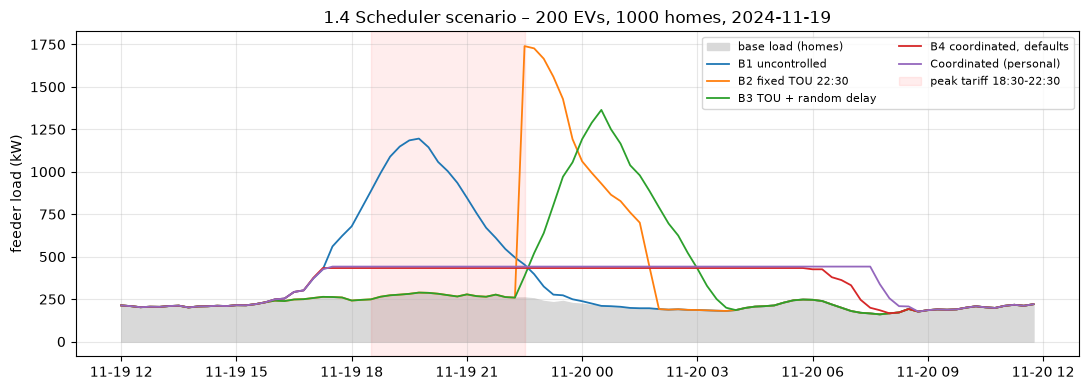

In [17]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.fill_between(idx, L, color="0.85", label="base load (homes)")
for name, p in strategies.items():
    ax.plot(idx, L + p.sum(axis=0), lw=1.3, label=name)
ax.axvspan(pd.Timestamp(DAY + " 18:30", tz="Asia/Colombo"), pd.Timestamp(DAY + " 22:30", tz="Asia/Colombo"),
           color="red", alpha=0.07, label="peak tariff 18:30-22:30")
ax.set_ylabel("feeder load (kW)"); ax.set_title(f"1.4 Scheduler scenario – {N_EV} EVs, {N_HOMES} homes, {DAY}")
ax.legend(fontsize=8, ncol=2); fig.tight_layout(); fig.savefig(FIG / "1_4_scheduler_scenario.png", dpi=120); plt.show()

## Save results
Metrics + configuration of this run are written to `results/` (golden rule 7).

In [18]:
def clean(o):
    if isinstance(o, dict): return {str(k): clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [clean(v) for v in o]
    if isinstance(o, (np.floating, float)): return None if np.isnan(o) else round(float(o), 4)
    if isinstance(o, np.integer): return int(o)
    return o
RESULTS["config"].update({"baseload_split": BASELOAD_SPLIT, "acn_split": SESSION_SPLITS["acn"],
                          "forecast_features": FEATS, "need_features": BASE_F, "cold_start_sessions": 10})
out = RES / f"c1_training_{RUN_ID}.json"
out.write_text(json.dumps(clean(RESULTS), indent=2))
print("saved", out.relative_to(ROOT))
# compare with the BEST baseline (honest): min MAE of seasonal-naive and yesterday
best_baseline = lambda m: min(m["seasonal_naive_last_week"]["MAE"], m["naive_yesterday"]["MAE"])
summary = pd.DataFrame({
    "1.1a base load MAE (kW/home)": [best_baseline(RESULTS["metrics"]["1.1a_baseload_forecast"]),
                                    RESULTS["metrics"]["1.1a_baseload_forecast"]["xgboost"]["MAE"]],
    "1.1b EV demand MAE (kW)": [best_baseline(RESULTS["metrics"]["1.1b_ev_demand_forecast"]),
                                RESULTS["metrics"]["1.1b_ev_demand_forecast"]["xgboost"]["MAE"]],
    "1.3 departure MAE (min, warm)": [need_res["warm_only"]["departure_MAE_min_default"], need_res["warm_only"]["departure_MAE_min_personal"]],
    "1.3 energy MAE (kWh, warm)": [need_res["warm_only"]["energy_MAE_kWh_default"], need_res["warm_only"]["energy_MAE_kWh_personal"]],
}, index=["baseline", "proposed"]).T.round(3)
summary["improvement_%"] = (100 * (1 - summary.proposed / summary.baseline)).round(1)
summary["proposed_better"] = summary.proposed < summary.baseline
RESULTS["summary_vs_best_baseline"] = summary.reset_index().to_dict(orient="records")
out.write_text(json.dumps(clean(RESULTS), indent=2))
display(summary)

saved charging_scheduling\results\c1_training_20261019T090804Z.json


,baseline,proposed,improvement_%,proposed_better
1.1a base load MAE (kW/home),0.013,0.013,0.0,False
1.1b EV demand MAE (kW),18.402,12.602,31.5,True
"1.3 departure MAE (min, warm)",101.544,85.595,15.7,True
"1.3 energy MAE (kWh, warm)",7.283,3.893,46.5,True


## ✅ Model accuracy summary (test period)

Forecasting / prediction models output numbers, so accuracy is shown as **error** (smaller = better):
* **MAE** – average size of the error (same unit as the target).
* **WAPE %** – total error as a % of the total real value. **Accuracy % = 100 − WAPE**.
* For departure time also: share of predictions within **±30 min** and **±60 min** of the real departure.

Every proposed model is shown next to its baseline, on the **same test rows** never used in training.

In [19]:
rows = []
for key, label, unit in (("1.1a_baseload_forecast", "1.1a Base-load forecast", "kW/home"),
                         ("1.1b_ev_demand_forecast", "1.1b EV demand forecast", "kW")):
    m = RESULTS["metrics"][key]
    for meth, name in (("seasonal_naive_last_week", "baseline: same time last week"),
                       ("naive_yesterday", "baseline: same time yesterday"), ("xgboost", "XGBoost (proposed)")):
        rows.append({"model": label, "method": name, "MAE": m[meth]["MAE"], "unit": unit,
                     "RMSE": m[meth]["RMSE"], "WAPE_%": m[meth]["WAPE_%"], "accuracy_%": 100 - m[meth]["WAPE_%"]})

w = te[te.prev_n >= 10]                                # drivers with >= 10 past sessions (warm)
d_stay, d_kwh = profile_default(w)
p_stay = models["stay_personal"].predict(w[BASE_F]); p_kwh = models["kwh_personal"].predict(w[BASE_F])
for name, ps, pk in (("baseline: profile default", d_stay, d_kwh), ("XGBoost personal (proposed)", p_stay, p_kwh)):
    err_min = np.abs(w.stay_h - ps) * 60
    rows.append({"model": "1.3 Departure time", "method": name, "MAE": float(err_min.mean()), "unit": "min",
                 "RMSE": rmse(w.stay_h * 60, ps * 60), "WAPE_%": wape(w.stay_h, ps), "accuracy_%": 100 - wape(w.stay_h, ps),
                 "within_30min_%": 100 * float((err_min <= 30).mean()), "within_60min_%": 100 * float((err_min <= 60).mean())})
    rows.append({"model": "1.3 Energy need", "method": name, "MAE": mae(w.kwh, pk), "unit": "kWh",
                 "RMSE": rmse(w.kwh, pk), "WAPE_%": wape(w.kwh, pk), "accuracy_%": 100 - wape(w.kwh, pk)})
q10 = models["stay_q10"].predict(w[BASE_F])
ACC = pd.DataFrame(rows)
RESULTS["accuracy_table"] = ACC.round(4).to_dict(orient="records")
RESULTS["metrics"]["1.3_q10_safe_departure_coverage_%"] = 100 * float(np.mean(w.stay_h >= q10))
out.write_text(json.dumps(clean(RESULTS), indent=2))
ACC.to_csv(RES / f"c1_accuracy_{RUN_ID}.csv", index=False)

def highlight(r):
    return ["font-weight: bold; background-color: #e8f5e9" if "proposed" in r["method"] else "" for _ in r]
display(ACC.style.apply(highlight, axis=1).format(
    {"MAE": "{:.3f}", "RMSE": "{:.3f}", "WAPE_%": "{:.1f}", "accuracy_%": "{:.1f}",
     "within_30min_%": "{:.1f}", "within_60min_%": "{:.1f}"}, na_rep="–").hide(axis="index"))
print(f"1.3 safe departure (q10): car still parked at predicted time in {RESULTS['metrics']['1.3_q10_safe_departure_coverage_%']:.1f} % of cases (target ~90 %)")
print(f"1.2 routine clustering: silhouette = {RESULTS['metrics']['1.2_routine_clustering']['silhouette']:.2f} (0 = no structure, 1 = perfect), k = {K}")

model,method,MAE,unit,RMSE,WAPE_%,accuracy_%,within_30min_%,within_60min_%
1.1a Base-load forecast,baseline: same time last week,0.022,kW/home,0.029,9.8,90.2,–,–
1.1a Base-load forecast,baseline: same time yesterday,0.013,kW/home,0.018,5.7,94.3,–,–
1.1a Base-load forecast,XGBoost (proposed),0.013,kW/home,0.018,5.9,94.1,–,–
1.1b EV demand forecast,baseline: same time last week,18.402,kW,35.417,45.7,54.3,–,–
1.1b EV demand forecast,baseline: same time yesterday,24.896,kW,47.109,61.9,38.1,–,–
1.1b EV demand forecast,XGBoost (proposed),12.602,kW,22.536,31.3,68.7,–,–
1.3 Departure time,baseline: profile default,101.544,min,157.177,25.2,74.8,29.5,50.8
1.3 Energy need,baseline: profile default,7.283,kWh,11.208,53.1,46.9,–,–
1.3 Departure time,XGBoost personal (proposed),85.595,min,126.554,21.3,78.7,29.8,53.1
1.3 Energy need,XGBoost personal (proposed),3.893,kWh,6.340,28.4,71.6,–,–


1.3 safe departure (q10): car still parked at predicted time in 87.2 % of cases (target ~90 %)
1.2 routine clustering: silhouette = 0.47 (0 = no structure, 1 = perfect), k = 2


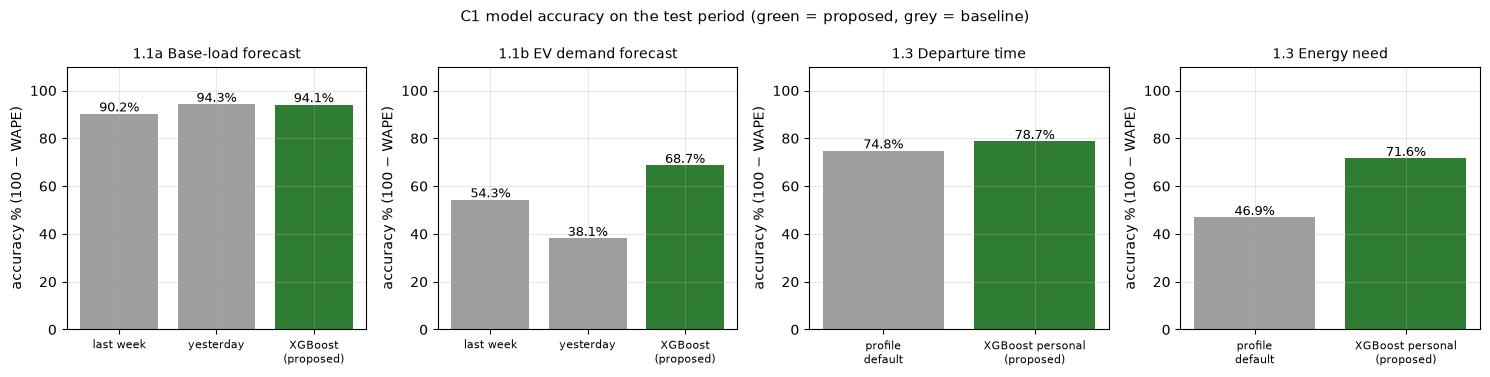

1.4 Scheduler (scenario) – measured by peak and car-ready rate, not accuracy:


,peak_kW,peak_reduction_vs_B1_%,car_ready_%,EV_cost_LKR_per_car
B1 uncontrolled,1195.4,0.0,100.0,958.4
B2 fixed TOU 22:30,1739.8,-45.5,100.0,335.7
B3 TOU + random delay,1364.1,-14.1,100.0,335.7
"B4 coordinated, defaults",433.2,63.8,49.5,489.9
Coordinated (personal),441.8,63.0,100.0,553.9


In [20]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8))
colors = lambda df: ["#2e7d32" if "proposed" in m else "#9e9e9e" for m in df.method]
for ax, model in zip(axes, ACC.model.unique()):
    d = ACC[ACC.model == model]
    ax.bar(range(len(d)), d["accuracy_%"], color=colors(d))
    for i, v in enumerate(d["accuracy_%"]):
        ax.text(i, v + 1, f"{v:.1f}%", ha="center", fontsize=9)
    ax.set_xticks(range(len(d))); ax.set_xticklabels([m.replace("baseline: ", "").replace("same time ", "").replace("profile ", "profile\n").replace(" (proposed)", "\n(proposed)") for m in d.method], fontsize=8, rotation=0)
    ax.set_ylim(0, 110); ax.set_title(model, fontsize=10); ax.set_ylabel("accuracy % (100 − WAPE)")
fig.suptitle("C1 model accuracy on the test period (green = proposed, grey = baseline)", fontsize=11)
fig.tight_layout(); fig.savefig(FIG / "c1_accuracy_summary.png", dpi=120); plt.show()

sched = pd.DataFrame(RESULTS["metrics"]["1.4_scheduler_scenario"]["results"]).T[["peak_kW", "peak_reduction_vs_B1_%", "car_ready_%", "EV_cost_LKR_per_car"]]
print("1.4 Scheduler (scenario) – measured by peak and car-ready rate, not accuracy:")
display(sched.round(1))

## Notes for the thesis / next steps
* **1.1:** compare against the **best** baseline. For the household base load the simple "same time yesterday"
  forecast is already very strong; XGBoost must beat it to claim an improvement. XGBoost is used (TensorFlow is not available on this Python 3.14 setup). Add LSTM/GRU in a Python 3.11
  environment and compare on the same test rows.
* **1.2:** routine types here are *workplace* patterns (ACN/Utrecht). Re-run on Sri Lankan pilot sessions.
* **1.3:** ACN app inputs exist for part of the sessions only; the personal model needs ≥ 10 past sessions.
* **1.4:** this is a scenario with simulated arrivals/departures (allowed for scenarios only). Next: feed the
  1.3 predictions (q10 departure) into the scheduler, run 10k / 50k / 100k EVs and 50 / 80 / 100 % compliance,
  and a rolling 24 h (MPC) version.